<img src="https://fedesarrollo.org.co/logo-Fede.png" alt="Fedesarrollo" style="float: right; width: 300px; height: auto;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f9/Logo_BID_Espa%C3%B1ol.png" alt="Banco Interamericano de Desarrollo" style="float: right; width: 220px; height: auto;">

# Priorización de industrias y macrosectores según potencial exportador

Editor: Juan Diego Heredia Niño - jheredia@fedesarrollo.org.co

Septiembre 2026

### Importar librerías

La siguiente celda marca el inicio de un nuevo bloque de trabajo independiente:

**Librerías utilizadas:**
- `pandas` y `numpy`: para manipulación y análisis de datos estructurados.
- `matplotlib.pyplot`: para las figuras de área apilada.
- `collections.defaultdict`: para acumular los resultados de la simulación.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

### Configuración de rutas

Carga las rutas del proyecto y las opciones globales desde `config.py`, instalado como
paquete editable en la raíz del proyecto.

In [2]:
from config import raw, temp, processed, figures, tables, random_state, colores_industrias, colores_macrosectores

plt.style.use('ggplot')

### Parámetros

Define los valores que controlan la simulación Monte Carlo y la proyección: la fracción de
productos que se muestrea de cada industria, el número de iteraciones, cuántas industrias entran
a la proyección y los valores inicial y final del índice reescalado.

La semilla se fija aquí para que la simulación sea reproducible.

In [3]:
porcentaje_min   = 0.10   # Proporción mínima de productos a muestrear por industria
porcentaje_max   = 0.20   # Proporción máxima de productos a muestrear por industria
num_iteraciones  = 1000   # Número de iteraciones de la simulación
top_n_industrias = 10     # Número de industrias para la proyección
valor_inicial    = 0      # Valor de exportaciones en período inicial
valor_final      = 100    # Valor de exportaciones en período final

# SEMILLA: el notebook original corria las dos simulaciones Monte Carlo sin fijarla, y por eso
# el deck y el capitulo reportan cifras distintas para la misma tabla. Ver
# tools/markdown/AUDITORIA_MIGRACION.md, hallazgo 2.1
np.random.seed(random_state)

### Lectura de datos

Carga la lista de productos con oportunidad identificada, los de AmCham, la correspondencia
entre nomenclaturas arancelarias, la clasificación por clase de negocio, las predicciones de
ganancia exportadora y el índice de proyección a veinte años.

In [4]:
# Lee lista de productos con tipo de oportunidad
df_productos = (
    pd.read_excel(
        raw / 'exportaciones' / 'productos' / '2 - Output Final 040725 V02 - EXT.xlsx',
        sheet_name='Productos únicos'
    )
    .rename(columns={'HS6': 'hs6_2012', 'Margen': 'tipo_oportunidad'})
    [['hs6_2012', 'tipo_oportunidad']]
    .drop_duplicates()
)
df_productos['hs6_2012'] = df_productos['hs6_2012'].astype(str).str.zfill(6)

# Lee productos de AmCham
df_productos_amcham = (
    pd.read_parquet(temp / 'df_amcham.parquet')
    .rename(columns={'HS6': 'hs6_2012', 'Margen': 'tipo_oportunidad', 'Industria': 'industria'})
    [['hs6_2012', 'tipo_oportunidad']]
    .drop_duplicates()
)

# Lee tabla de correspondencia HS 2012 a HS 1996
df_hs96 = (
    pd.read_excel(
        raw / 'comercio' / 'correlativas' / 'HS 2012 to HS 1996 Correlation and conversion tables.xls',
        header=6,
        sheet_name='Conversion HS 2012-HS 1996'
    )
    .drop(columns=['Unnamed: 0', 'Unnamed: 1'])
    .rename(columns={'HS 1996': 'hs6_1996', 'HS 2012': 'hs6_2012'})
    [['hs6_1996', 'hs6_2012']]
)
df_hs96['hs6_1996'] = df_hs96['hs6_1996'].astype(str).str.zfill(6)
df_hs96['hs6_2012'] = df_hs96['hs6_2012'].astype(str).str.zfill(6)

# Lee clasificación CIIU por producto
df_ciiu = (
    pd.read_excel(
        raw / 'exportaciones' / 'productos' / '2 - Output Final 040725 V02 - EXT.xlsx',
        sheet_name='Productos únicos'
    )
    [['HS6', 'CIIU']]
)
df_ciiu['hs6_2012'] = df_ciiu['HS6'].astype(str).str.zfill(6)
df_ciiu = df_ciiu.drop(columns=['HS6'])
df_ciiu['CIIU'] = df_ciiu['CIIU'].astype(str).str.zfill(4)

# Lee clasificación agregada por clase de negocio
df_ciiu_agg = (
    pd.read_excel(raw / 'ciiu' / 'CIIU_Clasificacion_Actualizada.xlsx')
    .dropna()
    [['CIIU', 'Clase de Negocio']]
)
df_ciiu_agg['CIIU'] = df_ciiu_agg['CIIU'].astype(float).astype(int).astype(str).str.zfill(4)

# Lee predicciones de exportación por código HS 1996
df_predicciones = (
    pd.read_parquet(processed / 'predicciones_proyeccion.parquet')
    .groupby('hs6_1996')['Prediction'].sum()
    .reset_index()
)

# Lee índices normalizados de proyección
indices = pd.read_parquet(temp / 'modelo' / 'indices_normalizados_20anios.parquet')

### Consolidación

Asocia cada producto con su predicción de ganancia exportadora y su clase de negocio, y agrega
la predicción por producto y clase.

In [5]:
# Consolida listas de productos con oportunidades de exportación
df_products = (
    pd.concat([df_productos, df_productos_amcham], ignore_index=True)
    .drop_duplicates()
    .reset_index(drop=True)
)

# Construye tabla principal con predicciones por producto y clase de negocio
df = (
    df_predicciones
    .merge(df_hs96, how='left', on='hs6_1996')
    .merge(df_products[['hs6_2012']], how='inner', on='hs6_2012')
    .drop(columns=['hs6_1996'])
    .drop_duplicates()
    .merge(df_ciiu, how='inner', on='hs6_2012')
    .merge(df_ciiu_agg, how='left', on='CIIU')
    .groupby(['Clase de Negocio', 'hs6_2012'])['Prediction'].sum()
    .reset_index()
    .rename(columns={'Clase de Negocio': 'CIIU'})
)

### Simulación Monte Carlo por industria

Estima el potencial de cada industria con mil iteraciones. En cada una selecciona al azar entre
el diez y el veinte por ciento de los productos de la industria y suma sus predicciones. El
promedio de las iteraciones es el estimador del potencial, y con él se construye el ranking.

In [6]:
# Ejecuta simulación Monte Carlo para estimar potencial de exportación por industria
resultados_iteraciones = defaultdict(list)
productos_por_ciiu = df.groupby('CIIU')

for k in range(num_iteraciones):
    for ciiu, grupo in productos_por_ciiu:
        porcentaje = np.random.uniform(porcentaje_min, porcentaje_max)
        n_muestra = max(1, int(len(grupo) * porcentaje))
        muestra = grupo.sample(n=n_muestra, replace=False)
        resultados_iteraciones[ciiu].append(muestra['Prediction'].sum())

# Calcula estadísticas por industria y construye ranking
resultados = []
for ciiu, valores in resultados_iteraciones.items():
    grupo_ciiu = df.query('CIIU == @ciiu')
    resultados.append({
        'CIIU': ciiu,
        'Exp_c_promedio': np.mean(valores),
        'Exp_c_total': grupo_ciiu['Prediction'].sum(),
        'Exp_c_std': np.std(valores),
        'Exp_c_min': np.min(valores),
        'Exp_c_max': np.max(valores),
        'n_productos': len(grupo_ciiu)
    })

df_ranking = (
    pd.DataFrame(resultados)
    .sort_values('Exp_c_promedio', ascending=False)
    .reset_index(drop=True)
)
df_ranking['ranking'] = range(1, len(df_ranking) + 1)
df_ranking

,CIIU,Exp_c_promedio,Exp_c_total,Exp_c_std,Exp_c_min,Exp_c_max,n_productos,ranking
0,Industria de maquinaria y transporte,"20,451,875.22","138,971,874.74","6,981,440.39","5,223,638.80","43,433,653.55",123,1
1,Productos equipos de potencia y distribución e...,"14,464,619.74","102,277,204.84","5,241,986.14","2,646,111.17","33,031,092.78",67,2
2,Metales derivados de materiales reciclados,"11,069,948.71","76,540,644.99","2,517,556.17","5,370,116.71","17,582,953.61",79,3
3,Sector farmacéutico,"5,669,136.16","39,565,146.37","1,830,933.47","1,721,783.36","12,018,863.31",99,4
4,Otros,"5,645,707.32","45,791,030.39","2,692,505.60","331,366.76","14,900,464.51",17,5
5,Textiles y confección,"4,661,638.72","32,786,479.80","1,989,231.82","1,317,177.85","12,674,939.19",60,6
6,Derivados petróleo básicos,"3,919,394.91","39,545,904.24","2,435,690.32","577,180.12","9,449,771.66",10,7
7,Minería,"3,884,159.16","30,575,149.87","1,764,280.30","721,657.93","9,765,332.16",23,8
8,Madera,"3,252,977.08","9,884,276.97","1,066,077.97","1,806,573.75","4,050,124.20",3,9
9,Plásticos y caucho,"2,360,830.28","17,896,456.43","1,029,154.53","435,112.20","5,937,039.14",35,10


### Participación por industria

Calcula la participación de cada industria sobre el total estimado y selecciona las diez de
mayor potencial, normalizando sus participaciones.

In [7]:
# Calcula participación de cada industria sobre el total estimado
e_total = df_ranking['Exp_c_promedio'].sum()
df_ranking['Share'] = df_ranking['Exp_c_promedio'] / e_total

# Selecciona top industrias y normaliza si es necesario
proporciones = df_ranking[['CIIU', 'Share']].head(top_n_industrias).copy()
total_share = proporciones['Share'].sum()
if abs(total_share - 1.0) > 0.01:
    proporciones['Share'] = proporciones['Share'] / total_share

proporciones

,CIIU,Share
0,Industria de maquinaria y transporte,0.27
1,Productos equipos de potencia y distribución e...,0.19
2,Metales derivados de materiales reciclados,0.15
3,Sector farmacéutico,0.08
4,Otros,0.07
5,Textiles y confección,0.06
6,Derivados petróleo básicos,0.05
7,Minería,0.05
8,Madera,0.04
9,Plásticos y caucho,0.03


### Proyección por industria

Reescala el índice normalizado entre los valores inicial y final, y reparte el valor total de
cada período entre las industrias seleccionadas según su participación.

In [8]:
# Reescala índice normalizado entre valor_inicial y valor_final
indice_inicial = indices.loc[indices['periodo'] == 0, 'indice_normalizado'].values[0]
indice_final   = indices.loc[indices['periodo'] == 19, 'indice_normalizado'].values[0]

indices['valor_total'] = valor_inicial + (valor_final - valor_inicial) * (
    (indices['indice_normalizado'] - indice_inicial) / (indice_final - indice_inicial)
)

# Calcula proyección por industria y período
proyecciones_industrias = []
for _, row_periodo in indices.iterrows():
    valores_industrias = {'periodo': int(row_periodo['periodo'])}
    for _, row_industria in proporciones.iterrows():
        ciiu = str(row_industria['CIIU'])
        valores_industrias[ciiu] = row_periodo['valor_total'] * row_industria['Share']
    proyecciones_industrias.append(valores_industrias)

df_proyecciones = pd.DataFrame(proyecciones_industrias)
df_proyecciones

,periodo,Industria de maquinaria y transporte,Productos equipos de potencia y distribución eléctrica,Metales derivados de materiales reciclados,Sector farmacéutico,Otros,Textiles y confección,Derivados petróleo básicos,Minería,Madera,Plásticos y caucho
0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1,1.85,1.31,1.00,0.51,0.51,0.42,0.35,0.35,0.29,0.21
2,2,3.08,2.18,1.67,0.85,0.85,0.70,0.59,0.59,0.49,0.36
3,3,4.64,3.28,2.51,1.29,1.28,1.06,0.89,0.88,0.74,0.54
4,4,5.79,4.09,3.13,1.60,1.60,1.32,1.11,1.10,0.92,0.67
5,5,6.98,4.94,3.78,1.94,1.93,1.59,1.34,1.33,1.11,0.81
6,6,8.28,5.85,4.48,2.29,2.28,1.89,1.59,1.57,1.32,0.96
7,7,9.58,6.78,5.19,2.66,2.64,2.18,1.84,1.82,1.52,1.11
8,8,10.88,7.70,5.89,3.02,3.00,2.48,2.09,2.07,1.73,1.26
9,9,12.44,8.80,6.73,3.45,3.43,2.84,2.38,2.36,1.98,1.44


### Figura de proyección por industria

Área apilada de la participación acumulada de la ganancia exportadora a lo largo de los veinte
períodos. Es la figura que trae el capítulo en su versión V04.

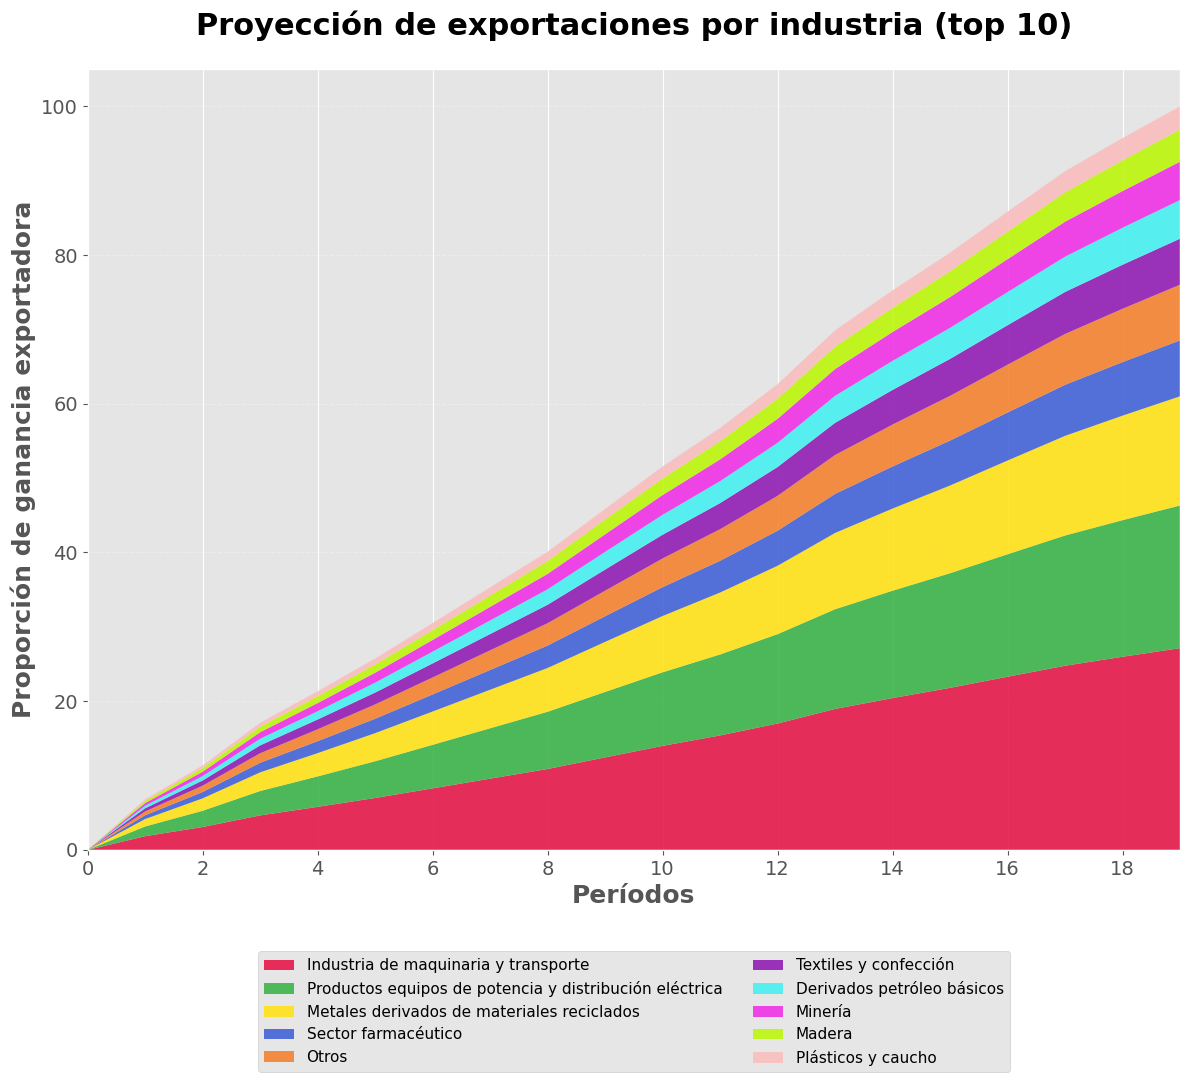

In [9]:
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

colores = colores_industrias  # definida en config.py

industrias_cols = [col for col in df_proyecciones.columns if col != 'periodo']
valores_finales = {col: df_proyecciones[col].iloc[-1] for col in industrias_cols}
industrias_ordenadas = sorted(valores_finales.items(), key=lambda x: x[1], reverse=True)

industrias_data = [df_proyecciones[ind].values for ind, _ in industrias_ordenadas]
labels = [ind for ind, _ in industrias_ordenadas]

fig, ax = plt.subplots(figsize=(12, 11))

ax.stackplot(
    df_proyecciones['periodo'], * industrias_data,
    labels=labels,
    colors=colores[:len(industrias_data)],
    alpha=0.9
)

ax.set_xlabel('Períodos', fontsize=18, fontweight='bold')
ax.set_ylabel('Proporción de ganancia exportadora', fontsize=18, fontweight='bold')
ax.set_title('Proyección de exportaciones por industria (top 10)', fontsize=22, fontweight='bold', pad=25)
ax.legend(loc='upper center', fontsize=11, ncol=2, framealpha=0.95, bbox_to_anchor=(0.5, -0.12))
ax.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.8)
ax.set_xlim(0, 19)
ax.set_xticks(range(0, 20, 2))
ax.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
plt.savefig(figures / 'proyeccion_industrias.png', dpi=300, bbox_inches='tight')
plt.show()

### Tablas de industrias

Exporta el ranking en tres formatos: la participación en LaTeX, las veinte primeras industrias
con valores en billones de dólares en LaTeX, y el ranking completo en valores separados por
comas. La tabla de participación es la que alimenta la tabla 3 del capítulo.

In [10]:
tables.mkdir(parents=True, exist_ok=True)

# Exporta tabla de participación por industria en LaTeX
df_latex = (
    df_ranking[['CIIU', 'Share', 'n_productos']]
    .rename(columns={'CIIU': 'Industria', 'Share': 'Participación', 'n_productos': 'Número de productos'})
)
df_latex['Participación'] = df_latex['Participación'].apply(lambda x: f'{x:.2%}')
df_latex.to_latex(tables / 'participacion_industrias.tex', index=False)

# Exporta tabla del top 20 en LaTeX con valores en billones de USD
top20 = df_ranking.head(20).copy()
top20['Exp_c_promedio_billones'] = (top20['Exp_c_promedio'] / 1_000_000).round(3)
top20['Exp_c_total_billones']    = (top20['Exp_c_total']    / 1_000_000).round(3)

(
    top20[['ranking', 'CIIU', 'Exp_c_promedio_billones', 'Exp_c_total_billones', 'n_productos']]
    .rename(columns={
        'ranking': 'Ranking',
        'Exp_c_promedio_billones': 'Promedio (Billones USD)',
        'Exp_c_total_billones': 'Total (Billones USD)',
        'n_productos': 'N Productos'
    })
    .to_latex(tables / 'top20_ciiu_billones.tex', index=False)
)

# Exporta ranking completo en CSV con valores en billones de USD
df_export = df_ranking[[
    'ranking', 'CIIU', 'Exp_c_promedio', 'Exp_c_total',
    'Exp_c_std', 'Exp_c_min', 'Exp_c_max', 'n_productos'
]].copy()
for col in ['Exp_c_promedio', 'Exp_c_total', 'Exp_c_std', 'Exp_c_min', 'Exp_c_max']:
    df_export[col] = df_export[col] / 1_000_000
df_export.columns = [
    'Ranking', 'CIIU', 'Exp_c_Promedio_Billones_USD', 'Exp_c_Total_Billones_USD',
    'Exp_c_Std_Billones_USD', 'Exp_c_Min_Billones_USD', 'Exp_c_Max_Billones_USD', 'Num_Productos'
]
df_export.to_csv(tables / 'ranking_ciiu_billones.csv', index=False)

### Simulación Monte Carlo por macrosector

Agrupa las veinticuatro industrias en cuatro macrosectores y repite la simulación a ese nivel.
La clase residual se desagrega por código CIIU: instrumentos médicos y odontológicos va a la
industria química y el resto a manufacturas avanzadas.

In [11]:
# Mapeo de Clase de Negocio a Macrosector
mapeo_macrosector = {
    'Frutas frescas y frutas procesadas':  'Agroindustria y Alimentos',
    'Cafés y cafes especiales':            'Agroindustria y Alimentos',
    'Carne bovina':                        'Agroindustria y Alimentos',
    'Pesca y acuicultura':                 'Agroindustria y Alimentos',
    'Azúcar y derivados primarios':        'Agroindustria y Alimentos',
    'Confitería':                          'Agroindustria y Alimentos',
    'Otros productos alimenticios':        'Agroindustria y Alimentos',

    'Cosméticos y productos de aseo personal': 'Industria Química, Farmacéutica y Bioproductos',
    'Agroquímicos y biológicos':               'Industria Química, Farmacéutica y Bioproductos',
    'Sector farmacéutico':                     'Industria Química, Farmacéutica y Bioproductos',
    'Plásticos y caucho':                      'Industria Química, Farmacéutica y Bioproductos',
    'Química básica':                          'Industria Química, Farmacéutica y Bioproductos',

    'Industria de maquinaria y transporte':                      'Manufacturas Avanzadas y Bienes Industriales',
    'Productos equipos de potencia y distribución eléctrica':    'Manufacturas Avanzadas y Bienes Industriales',
    'Metales derivados de materiales reciclados':                'Manufacturas Avanzadas y Bienes Industriales',
    'Metales a partir de material recuperado':                   'Manufacturas Avanzadas y Bienes Industriales',
    'Productos metálicos':                                       'Manufacturas Avanzadas y Bienes Industriales',
    'Papel y productos de papel':                                'Manufacturas Avanzadas y Bienes Industriales',
    'Madera':                                                    'Manufacturas Avanzadas y Bienes Industriales',
    'Textiles y confección':                                     'Manufacturas Avanzadas y Bienes Industriales',
    'Minerales no metálicos':                                    'Manufacturas Avanzadas y Bienes Industriales',

    'Minería':                     'Industrias Extractivas',
    'Derivados petróleo básicos':  'Industrias Extractivas',
}

# CIIUs de "Otros": 3250 va a Química, el resto a Manufacturas
ciiu_otros_quimica = {'3250'}

# Reconstruir df con CIIU original para poder separar "Otros"
df_macro = (
    df_predicciones
    .merge(df_hs96, how='left', on='hs6_1996')
    .merge(df_products[['hs6_2012']], how='inner', on='hs6_2012')
    .drop(columns=['hs6_1996'])
    .drop_duplicates()
    .merge(df_ciiu, how='inner', on='hs6_2012')
    .merge(df_ciiu_agg, how='left', on='CIIU')
    .rename(columns={'Clase de Negocio': 'industria', 'CIIU': 'ciiu_code'})
)

# Asignar macrosector: para "Otros" usar el código CIIU, para el resto usar el mapeo directo
def asignar_macrosector(row):
    if row['industria'] == 'Otros':
        if row['ciiu_code'] in ciiu_otros_quimica:
            return 'Industria Química, Farmacéutica y Bioproductos'
        else:
            return 'Manufacturas Avanzadas y Bienes Industriales'
    return mapeo_macrosector.get(row['industria'], 'Sin clasificar')

df_macro['Macrosector'] = df_macro.apply(asignar_macrosector, axis=1)

# Agrupar predicciones por macrosector y producto
df_macro = (
    df_macro
    .groupby(['Macrosector', 'hs6_2012'])['Prediction'].sum()
    .reset_index()
)

# Verificar que no hay "Sin clasificar"
print("Productos por macrosector:")
print(df_macro.groupby('Macrosector')['hs6_2012'].nunique())

# Simulación Monte Carlo por macrosector
resultados_iter_macro = defaultdict(list)
productos_por_macro = df_macro.groupby('Macrosector')

for k in range(num_iteraciones):
    for macro, grupo in productos_por_macro:
        porcentaje = np.random.uniform(porcentaje_min, porcentaje_max)
        n_muestra = max(1, int(len(grupo) * porcentaje))
        muestra = grupo.sample(n=n_muestra, replace=False)
        resultados_iter_macro[macro].append(muestra['Prediction'].sum())

# Construir ranking de macrosectores
resultados_macro = []
for macro, valores in resultados_iter_macro.items():
    grupo_macro = df_macro.query('Macrosector == @macro')
    resultados_macro.append({
        'Macrosector': macro,
        'Exp_c_promedio': np.mean(valores),
        'Exp_c_total': grupo_macro['Prediction'].sum(),
        'Exp_c_std': np.std(valores),
        'Exp_c_min': np.min(valores),
        'Exp_c_max': np.max(valores),
        'n_productos': len(grupo_macro)
    })

df_ranking_macro = (
    pd.DataFrame(resultados_macro)
    .sort_values('Exp_c_promedio', ascending=False)
    .reset_index(drop=True)
)
df_ranking_macro['ranking'] = range(1, len(df_ranking_macro) + 1)

# Calcular participación
e_total_macro = df_ranking_macro['Exp_c_promedio'].sum()
df_ranking_macro['Share'] = df_ranking_macro['Exp_c_promedio'] / e_total_macro

df_ranking_macro

Productos por macrosector:
Macrosector
Agroindustria y Alimentos                          73
Industria Química, Farmacéutica y Bioproductos    178
Industrias Extractivas                             33
Manufacturas Avanzadas y Bienes Industriales      378
Name: hs6_2012, dtype: int64


,Macrosector,Exp_c_promedio,Exp_c_total,Exp_c_std,Exp_c_min,Exp_c_max,n_productos,ranking,Share
0,Manufacturas Avanzadas y Bienes Industriales,"65,279,224.56","435,442,292.96","15,761,238.47","23,223,258.64","109,084,639.42",378,1,0.70
1,"Industria Química, Farmacéutica y Bioproductos","12,378,642.65","84,251,608.86","3,322,913.80","4,614,604.27","23,565,018.60",178,2,0.13
2,Industrias Extractivas,"9,478,799.78","70,121,054.10","4,426,577.40","1,253,556.46","26,514,514.60",33,3,0.10
3,Agroindustria y Alimentos,"6,577,178.83","46,075,692.36","1,651,511.59","2,861,306.46","11,677,354.25",73,4,0.07


### Proyección por macrosector

Reparte el valor total de cada período entre los cuatro macrosectores según su participación.

In [12]:
# Participaciones por macrosector (todos entran, no hay top_n)
proporciones_macro = df_ranking_macro[['Macrosector', 'Share']].copy()

# Proyección por macrosector y período
proyecciones_macro = []
for _, row_periodo in indices.iterrows():
    valores = {'periodo': int(row_periodo['periodo'])}
    for _, row_macro in proporciones_macro.iterrows():
        macro = str(row_macro['Macrosector'])
        valores[macro] = row_periodo['valor_total'] * row_macro['Share']
    proyecciones_macro.append(valores)

df_proyecciones_macro = pd.DataFrame(proyecciones_macro)
df_proyecciones_macro

,periodo,Manufacturas Avanzadas y Bienes Industriales,"Industria Química, Farmacéutica y Bioproductos",Industrias Extractivas,Agroindustria y Alimentos
0,0,0.00,0.00,0.00,0.00
1,1,4.74,0.90,0.69,0.48
2,2,7.91,1.50,1.15,0.80
3,3,11.91,2.26,1.73,1.20
4,4,14.86,2.82,2.16,1.50
5,5,17.93,3.40,2.60,1.81
6,6,21.25,4.03,3.09,2.14
7,7,24.60,4.66,3.57,2.48
8,8,27.94,5.30,4.06,2.81
9,9,31.94,6.06,4.64,3.22


### Figura de proyección por macrosector

Área apilada equivalente a la de industrias, al nivel de los cuatro macrosectores.

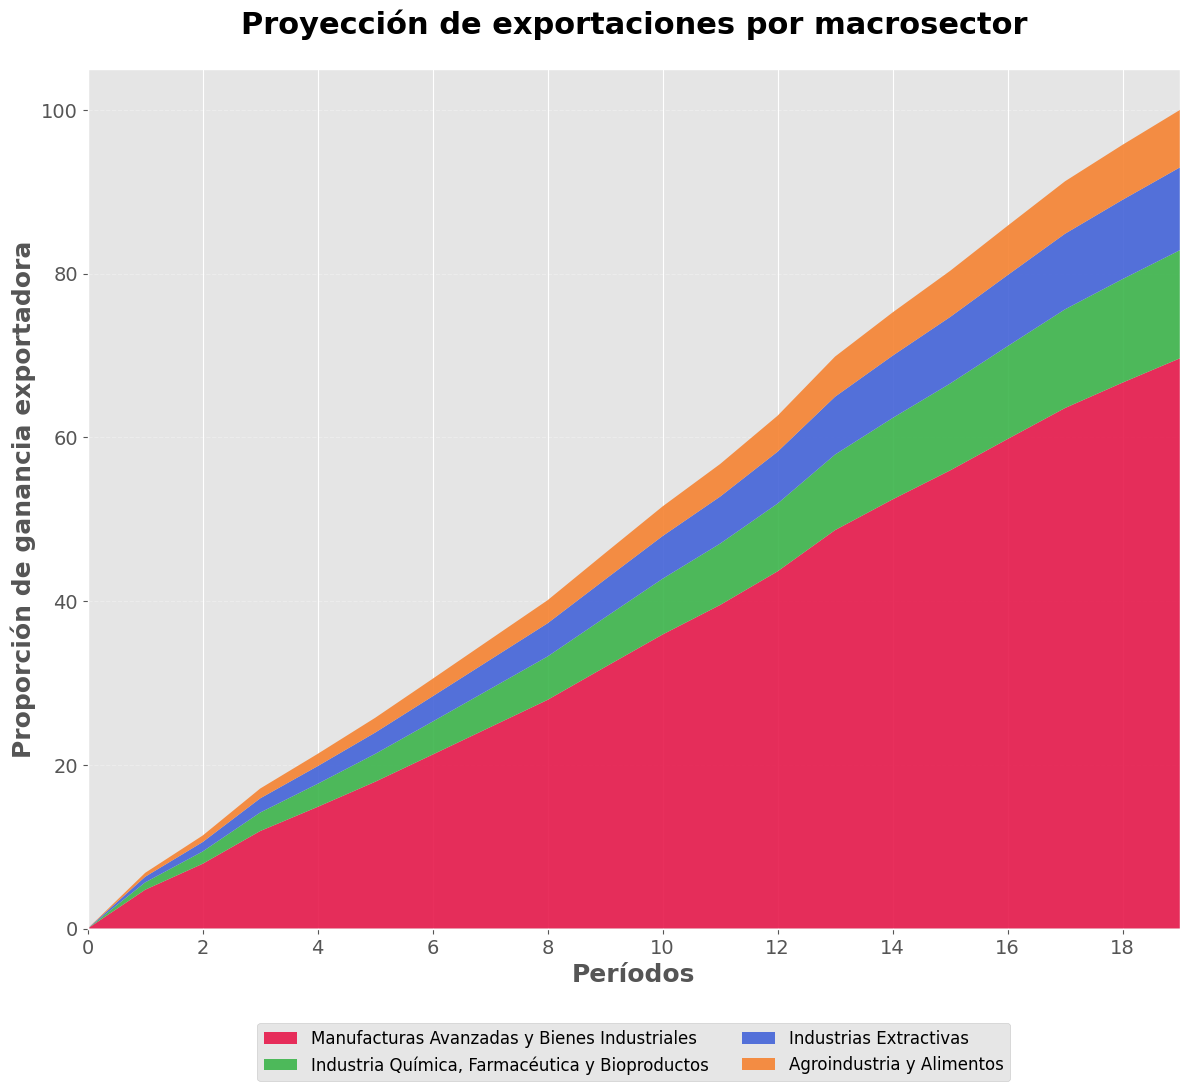

In [13]:
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

colores_macro = colores_macrosectores  # definida en config.py

macro_cols = [col for col in df_proyecciones_macro.columns if col != 'periodo']
valores_finales_macro = {col: df_proyecciones_macro[col].iloc[-1] for col in macro_cols}
macros_ordenados = sorted(valores_finales_macro.items(), key=lambda x: x[1], reverse=True)

macros_data = [df_proyecciones_macro[m].values for m, _ in macros_ordenados]
labels_macro = [m for m, _ in macros_ordenados]

fig, ax = plt.subplots(figsize=(12, 11))

ax.stackplot(
    df_proyecciones_macro['periodo'], *macros_data,
    labels=labels_macro,
    colors=colores_macro[:len(macros_data)],
    alpha=0.9
)

ax.set_xlabel('Períodos', fontsize=18, fontweight='bold')
ax.set_ylabel('Proporción de ganancia exportadora', fontsize=18, fontweight='bold')
ax.set_title('Proyección de exportaciones por macrosector', fontsize=22, fontweight='bold', pad=25)
ax.legend(loc='upper center', fontsize=12, ncol=2, framealpha=0.95, bbox_to_anchor=(0.5, -0.10))
ax.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.8)
ax.set_xlim(0, 19)
ax.set_xticks(range(0, 20, 2))
ax.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
plt.savefig(figures / 'proyeccion_macrosectores.png', dpi=300, bbox_inches='tight')
plt.show()

### Tablas de macrosectores

Exporta el ranking de macrosectores. La tabla de participación y la de valores en billones son
las que alimentan la tabla 4 del capítulo.

In [14]:
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

# Exporta tabla de participación por macrosector en LaTeX
df_latex_macro = (
    df_ranking_macro[['Macrosector', 'Share', 'n_productos']]
    .rename(columns={'Macrosector': 'Macrosector', 'Share': 'Participación', 'n_productos': 'Número de productos'})
)
df_latex_macro['Participación'] = df_latex_macro['Participación'].apply(lambda x: f'{x:.2%}')
df_latex_macro.to_latex(tables / 'participacion_macrosectores.tex', index=False)

# Exporta tabla en LaTeX con valores en billones de USD
df_macro_billones = df_ranking_macro.copy()
df_macro_billones['Exp_c_promedio_billones'] = (df_macro_billones['Exp_c_promedio'] / 1_000_000).round(3)
df_macro_billones['Exp_c_total_billones']    = (df_macro_billones['Exp_c_total']    / 1_000_000).round(3)

(
    df_macro_billones[['ranking', 'Macrosector', 'Exp_c_promedio_billones', 'Exp_c_total_billones', 'n_productos']]
    .rename(columns={
        'ranking': 'Ranking',
        'Exp_c_promedio_billones': 'Promedio (Billones USD)',
        'Exp_c_total_billones': 'Total (Billones USD)',
        'n_productos': 'N Productos'
    })
    .to_latex(tables / 'ranking_macrosectores_billones.tex', index=False)
)

# Exporta ranking completo en CSV con valores en billones de USD
df_export_macro = df_ranking_macro[[
    'ranking', 'Macrosector', 'Exp_c_promedio', 'Exp_c_total',
    'Exp_c_std', 'Exp_c_min', 'Exp_c_max', 'n_productos'
]].copy()
for col in ['Exp_c_promedio', 'Exp_c_total', 'Exp_c_std', 'Exp_c_min', 'Exp_c_max']:
    df_export_macro[col] = df_export_macro[col] / 1_000_000
df_export_macro.columns = [
    'Ranking', 'Macrosector', 'Exp_c_Promedio_Billones_USD', 'Exp_c_Total_Billones_USD',
    'Exp_c_Std_Billones_USD', 'Exp_c_Min_Billones_USD', 'Exp_c_Max_Billones_USD', 'Num_Productos'
]
df_export_macro.to_csv(tables / 'ranking_macrosectores_billones.csv', index=False)